# Debug / visualise the SNEMI3D + Kasthuri crops

Cross-checks `docs/DATASETS.md` against the HDF5 files in `data/SNEMI3D/` and draws where every crop sits in the
Kasthuri et al. (2015) volume. Nothing is hard-coded except the two bounding boxes printed in the paper: crop
coordinates, sizes and file names are parsed from the doc, then compared with the file names, the HDF5 shapes and
the pixels themselves (AC3/AC4/cylinder are located inside the *cropping* and compared voxel by voxel).

Every check prints `PASS`, `FAIL`, `WARN` or `INFO`; the last cell lists everything that is not `PASS`.

Conventions used throughout (6 nm voxels, BossDB `kasthuri2015/em/cc` numbering): `x`/`y` ranges are half-open
`[start, end)`, `z` is a slice index, and the doc lists the AC3/AC4 z ranges as first-last slice (inclusive).
Arrays are `(z, y, x)`.

In [1]:
import json, os, re, time
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi

# ---- parameters: change and re-run ---------------------------------------------------------
AC_SLICE = 50          # stored slice index shown in the AC3 / AC4 panels
Z_BG = 1170            # global cc z of the overview background (inside AC3, AC4 and the cylinder)
CYL_FULL_SCAN = True   # True: read every cylinder label block (~30-60 s); False: every 4th block
# ---------------------------------------------------------------------------------------------


def find_repo(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "docs" / "DATASETS.md").is_file():
            return p
    raise FileNotFoundError("Open this notebook from inside the ncntm repo (docs/DATASETS.md not found).")


REPO = find_repo()
DOC = REPO / "docs" / "DATASETS.md"
DATA = Path(os.environ.get("NCNTM_DATA_DIR", REPO / "data")) / "SNEMI3D"
DOC_TEXT = DOC.read_text()
print("repo:", REPO)
print("doc :", DOC)
print("data:", DATA)

RESULTS = []   # (status, name, detail)


def check(name, ok, detail="", warn=False):
    status = "PASS" if ok else ("WARN" if warn else "FAIL")
    RESULTS.append((status, name, detail))
    print(f"[{status}] {name}" + (f"  --  {detail}" if detail else ""))


def info(name, detail=""):
    RESULTS.append(("INFO", name, detail))
    print(f"[INFO] {name}" + (f"  --  {detail}" if detail else ""))


_H = {}


def vol(fname):
    """Lazy handle on the `main` dataset of data/SNEMI3D/<fname>."""
    if fname not in _H:
        _H[fname] = h5py.File(DATA / fname, "r")
    return _H[fname]["main"]


def ncc(a, b):
    a = a.astype(np.float32).ravel()
    b = b.astype(np.float32).ravel()
    a -= a.mean()
    b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))


def compare(a, b):
    d = np.abs(a.astype(np.int16) - b.astype(np.int16))
    return dict(equal=bool((d == 0).all()), frac_equal=float((d == 0).mean()),
                mean_abs=float(d.mean()), max_abs=int(d.max()))

repo: /home/nvidia/ncntm
doc : /home/nvidia/ncntm/docs/DATASETS.md
data: /home/nvidia/ncntm/data/SNEMI3D


## 1. Parse `DATASETS.md` and check it against the files

In [2]:
def table_rows(text):
    rows = []
    for line in text.splitlines():
        if line.startswith("|") and not re.match(r"^\|[-| ]+\|$", line):
            rows.append([c.strip() for c in line.strip().strip("|").split("|")])
    return rows


ROWS = table_rows(DOC_TEXT)
i_main = next(i for i, r in enumerate(ROWS) if r[0] == "Dataset")
i_file = next(i for i, r in enumerate(ROWS) if r[:3] == ["Name", "Image", "Labels"])

# main table: SNEMI3D / Neurons rows only (COSEM3D lives in data/COSEM3D and is not part of this notebook)
MAIN = []
for r in ROWS[i_main + 1:]:
    if len(r) == 11 and r[0] in ("SNEMI3D", "Neurons"):
        x, y, z = (int(v) for v in re.findall(r"\d+", r[6]))        # "Size crop" is x x y x z
        MAIN.append(dict(name=r[3], size_xyz=(x, y, z), voxels=int(r[8].replace(",", "")), task=r[9], split=r[10]))

# image / labels table: name -> backticked file names
FILES = {}
for r in ROWS[i_file + 1:]:
    if len(r) == 3:
        FILES[r[0]] = dict(images=re.findall(r"`([^`]+)`", r[1]), labels=re.findall(r"`([^`]+)`", r[2]))

print(f"{len(MAIN)} crops in the main table, {len(FILES)} rows in the file table\n")
for m in MAIN:
    check(f"doc voxel count == x*y*z   [{m['name']}]",
          m["voxels"] == int(np.prod(m["size_xyz"])), f"{m['voxels']:,} vs {int(np.prod(m['size_xyz'])):,}")
    check(f"doc lists files for       [{m['name']}]", m["name"] in FILES)

# inventory: every file named in the doc must exist with the documented shape
inv = []
for m in MAIN:
    x, y, z = m["size_xyz"]
    f = FILES.get(m["name"], dict(images=[], labels=[]))
    for kind, names in (("image", f["images"]), ("labels", f["labels"])):
        for fn in names:
            if not (DATA / fn).is_file():
                check(f"file exists: {fn}", False)
                continue
            d = vol(fn)
            ok_shape = d.shape == (z, y, x)
            ok_dtype = (d.dtype == np.uint8) if kind == "image" else (d.dtype.kind == "u")
            check(f"{fn}: shape (z,y,x) == doc ({z},{y},{x})", ok_shape, str(d.shape))
            check(f"{fn}: dtype", ok_dtype, str(d.dtype))
            inv.append((m["name"], kind, fn, d.shape, str(d.dtype), d.chunks,
                        d.compression or "none", (DATA / fn).stat().st_size / 1e9))

# the SNEMI3D train/test row is not in the main table: same 1024 x 1024 x 100 stack
for name, f in FILES.items():
    if name not in {m["name"] for m in MAIN}:
        for fn in f["images"] + f["labels"]:
            ok = (DATA / fn).is_file() and vol(fn).shape == (100, 1024, 1024)
            check(f"{fn}: exists, shape (100,1024,1024)  [{name}]", ok)
            if (DATA / fn).is_file():
                d = vol(fn)
                inv.append((name, "image" if "inputs" in fn else "labels", fn, d.shape, str(d.dtype),
                            d.chunks, d.compression or "none", (DATA / fn).stat().st_size / 1e9))

# every h5 on disk should be documented, and vice versa
on_disk = sorted(p.name for p in DATA.glob("*.h5"))
documented = sorted({fn for f in FILES.values() for fn in f["images"] + f["labels"]})
check("every *.h5 in data/SNEMI3D is listed in DATASETS.md", on_disk == documented,
      f"undocumented={sorted(set(on_disk) - set(documented))} missing={sorted(set(documented) - set(on_disk))}")

print()
print(f"{'crop':24s} {'kind':7s} {'file':58s} {'shape (z,y,x)':20s} {'dtype':7s} {'chunks':16s} {'comp':6s} {'GB':>6s}")
for row in inv:
    print(f"{row[0]:24s} {row[1]:7s} {row[2]:58s} {str(row[3]):20s} {row[4]:7s} {str(row[5]):16s} {row[6]:6s} {row[7]:6.2f}")

6 crops in the main table, 7 rows in the file table

[PASS] doc voxel count == x*y*z   [AC3_em]  --  104,857,600 vs 104,857,600
[PASS] doc lists files for       [AC3_em]
[PASS] doc voxel count == x*y*z   [AC4_em]  --  104,857,600 vs 104,857,600
[PASS] doc lists files for       [AC4_em]
[PASS] doc voxel count == x*y*z   [AC3_cc]  --  104,857,600 vs 104,857,600
[PASS] doc lists files for       [AC3_cc]
[PASS] doc voxel count == x*y*z   [AC4_cc]  --  104,857,600 vs 104,857,600
[PASS] doc lists files for       [AC4_cc]
[PASS] doc voxel count == x*y*z   [Kasthuri cylinder (cc)]  --  4,350,000,000 vs 4,350,000,000
[PASS] doc lists files for       [Kasthuri cylinder (cc)]
[PASS] doc voxel count == x*y*z   [Kasthuri cropping (cc)]  --  52,545,411,072 vs 52,545,411,072
[PASS] doc lists files for       [Kasthuri cropping (cc)]
[PASS] AC3_em_inputs.h5: shape (z,y,x) == doc (100,1024,1024)  --  (100, 1024, 1024)
[PASS] AC3_em_inputs.h5: dtype  --  uint8
[PASS] AC3_labels.h5: shape (z,y,x) == doc (

In [3]:
# doc claim: the cropping is stored uncompressed with (16, 256, 256) chunks
CROP_FILE = FILES["Kasthuri cropping (cc)"]["images"][0]
CROP = vol(CROP_FILE)
check("cropping: uncompressed, chunks (16,256,256) as documented",
      CROP.compression is None and CROP.chunks == (16, 256, 256), f"{CROP.compression}, {CROP.chunks}")

# norm.json sidecars: min/max must cover the data (exact for the small stacks, sampled for the big ones)
for fn in documented:
    side = DATA / (fn + ".norm.json")
    if not side.is_file():
        if "labels" not in fn and "segmentation" not in fn:
            check(f"{fn}.norm.json exists", False)
        continue
    nm = json.loads(side.read_text())
    d = vol(fn)
    if (DATA / fn).stat().st_size < 1e9:
        arr = d[...]
        lo, hi, how = int(arr.min()), int(arr.max()), "exact"
    else:
        zs = list(range(0, d.shape[0], max(1, d.shape[0] // 10)))
        blk = np.concatenate([d[z][::4, ::4] for z in zs[:6]])   # a few slices, sub-sampled
        lo, hi, how = int(blk.min()), int(blk.max()), f"sampled ({len(zs[:6])} slices)"
    check(f"{fn}.norm.json covers the data", nm["min"] <= lo and nm["max"] >= hi,
          f"norm [{nm['min']:.0f}, {nm['max']:.0f}] vs data [{lo}, {hi}] ({how})", warn=True)

[PASS] cropping: uncompressed, chunks (16,256,256) as documented  --  None, (16, 256, 256)
[PASS] AC3_cc_inputs.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (exact)
[PASS] AC3_em_inputs.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (exact)
[PASS] AC4_cc_inputs.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (exact)
[PASS] AC4_em_inputs.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (exact)
[WARN] neurons_cc_5000x2900x300_x3000_y7200_z950_volume.h5.norm.json covers the data  --  norm [0, 251] vs data [0, 255] (sampled (6 slices))
[PASS] neurons_cc_5904x4816x1848_x2512_y4432_z0_volume.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (sampled (6 slices))
[PASS] test_em_inputs.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (exact)
[PASS] train_em_inputs.h5.norm.json covers the data  --  norm [0, 255] vs data [0, 255] (exact)


## 2. Crop coordinates: doc vs file names vs the paper

Doc numbers are parsed with regular expressions (a changed sentence makes the parse fail loudly). The only external
numbers are the bounding boxes in the Kasthuri et al. (2015) figure caption, given in 3 x 3 nm x/y voxels (twice the
6 nm grid used here).

In [4]:
def parse(pattern, label, flags=re.S):
    m = re.search(pattern, DOC_TEXT, flags)
    check(f"doc sentence parsed: {label}", m is not None)
    return [int(g) for g in m.groups()] if m else None


ac3 = parse(r"\*\*AC3\*\*: x (\d+)-(\d+), y (\d+)-(\d+), `images` z (\d+)-(\d+) / `cc` z (\d+)-(\d+)", "AC3 box")
ac4 = parse(r"\*\*AC4\*\*: x (\d+)-(\d+), y (\d+)-(\d+), `images` z (\d+)-(\d+) / `cc` z (\d+)-(\d+)", "AC4 box")
cyl = parse(r"\*\*Kasthuri cylinder\*\*: offset \(x, y, z\) = \((\d+), (\d+), (\d+)\)", "cylinder offset")
cro = parse(r"\*\*Kasthuri cropping\*\*:.*?x (\d+)-(\d+), y (\d+)-(\d+), z (\d+)-(\d+)", "cropping box")

CYL_VOL = FILES["Kasthuri cylinder (cc)"]["images"][0]
CYL_SEG = FILES["Kasthuri cylinder (cc)"]["labels"][0]

# regions in global cc coordinates, half-open [start, end) on every axis
REGIONS = {
    "cropping": dict(x=(cro[0], cro[1]), y=(cro[2], cro[3]), z=(cro[4], cro[5])),
    "AC3": dict(x=(ac3[0], ac3[1]), y=(ac3[2], ac3[3]), z=(ac3[6], ac3[7] + 1), z_images=(ac3[4], ac3[5] + 1)),
    "AC4": dict(x=(ac4[0], ac4[1]), y=(ac4[2], ac4[3]), z=(ac4[6], ac4[7] + 1), z_images=(ac4[4], ac4[5] + 1)),
}
sx, sy, sz = next(m for m in MAIN if m["name"].startswith("Kasthuri cylinder"))["size_xyz"]
REGIONS["cylinder"] = dict(x=(cyl[0], cyl[0] + sx), y=(cyl[1], cyl[1] + sy), z=(cyl[2], cyl[2] + sz))
CX0, CX1 = REGIONS["cropping"]["x"]
CY0, CY1 = REGIONS["cropping"]["y"]
CZ0, CZ1 = REGIONS["cropping"]["z"]


def size(r):
    return (r["x"][1] - r["x"][0], r["y"][1] - r["y"][0], r["z"][1] - r["z"][0])


for n, r in REGIONS.items():
    print(f"{n:9s} x {r['x']}  y {r['y']}  z {r['z']}  ->  size (x,y,z) = {size(r)}" +
          (f"   images z {r['z_images']}" if "z_images" in r else ""))
print()

# doc box size == documented crop size == HDF5 shape
for n, name in (("AC3", "AC3_cc"), ("AC4", "AC4_cc"), ("cylinder", "Kasthuri cylinder (cc)"),
                ("cropping", "Kasthuri cropping (cc)")):
    want = next(m for m in MAIN if m["name"] == name)["size_xyz"]
    check(f"{n}: size of the doc box == 'Size crop' column", size(REGIONS[n]) == want, f"{size(REGIONS[n])} vs {want}")

# the images layer is the cc layer shifted by 2
for n in ("AC3", "AC4"):
    r = REGIONS[n]
    check(f"{n}: images z == cc z - 2", r["z_images"] == (r["z"][0] - 2, r["z"][1] - 2), f"{r['z_images']} vs {r['z']}")

# file names encode the same offsets / sizes
m = re.search(r"(\d+)x(\d+)x(\d+)_x(\d+)_y(\d+)_z(\d+)", CYL_VOL)
check("cylinder file name == doc offset and size",
      tuple(map(int, m.groups())) == (sx, sy, sz, cyl[0], cyl[1], cyl[2]), CYL_VOL)
m = re.search(r"(\d+)x(\d+)x(\d+)_x(\d+)_y(\d+)_z(\d+)", CROP_FILE)
check("cropping file name == doc box",
      tuple(map(int, m.groups())) == (*size(REGIONS["cropping"]), CX0, CY0, CZ0), CROP_FILE)

# Kasthuri et al. (2015) figure caption, 3 x 3 nm voxels in x/y; (min, max) corners
PAPER = {"AC3": ((10944, 17424, 999), (12992, 19472, 1255)),
         "AC4": ((8800, 10880, 1099), (10848, 12928, 1199))}
for n, (lo, hi) in PAPER.items():
    r = REGIONS[n]
    check(f"{n}: paper bbox x,y / 2 == doc x,y", (lo[0] // 2, hi[0] // 2) == r["x"] and (lo[1] // 2, hi[1] // 2) == r["y"],
          f"paper x {lo[0] // 2}-{hi[0] // 2}, y {lo[1] // 2}-{hi[1] // 2}")
    check(f"{n}: doc cc z range lies inside the paper z range", lo[2] <= r["z"][0] and r["z"][1] <= hi[2],
          f"doc {r['z']} vs paper ({lo[2]}, {hi[2]})")
check("AC4: doc cc z range == whole paper z range (100 slices)",
      REGIONS["AC4"]["z"] == (PAPER["AC4"][0][2], PAPER["AC4"][1][2]))
check("AC3: doc z range == the top 100 of the paper's 256 slices",
      REGIONS["AC3"]["z"] == (PAPER["AC3"][1][2] - 100, PAPER["AC3"][1][2]) and PAPER["AC3"][1][2] - PAPER["AC3"][0][2] == 256)

# how much of each region lies inside the cropping
def overlap_frac(a, b):
    v = 1
    for ax in "xyz":
        v *= max(0, min(a[ax][1], b[ax][1]) - max(a[ax][0], b[ax][0]))
    return v / np.prod(size(a))


print()
for n in ("AC3", "AC4", "cylinder"):
    info(f"{n}: fraction of the region inside the cropping", f"{overlap_frac(REGIONS[n], REGIONS['cropping']):.1%}")

[PASS] doc sentence parsed: AC3 box
[PASS] doc sentence parsed: AC4 box
[PASS] doc sentence parsed: cylinder offset
[PASS] doc sentence parsed: cropping box
cropping  x (2512, 8416)  y (4432, 9248)  z (0, 1848)  ->  size (x,y,z) = (5904, 4816, 1848)
AC3       x (5472, 6496)  y (8712, 9736)  z (1155, 1255)  ->  size (x,y,z) = (1024, 1024, 100)   images z (1153, 1253)
AC4       x (4400, 5424)  y (5440, 6464)  z (1099, 1199)  ->  size (x,y,z) = (1024, 1024, 100)   images z (1097, 1197)
cylinder  x (3000, 8000)  y (7200, 10100)  z (950, 1250)  ->  size (x,y,z) = (5000, 2900, 300)

[PASS] AC3: size of the doc box == 'Size crop' column  --  (1024, 1024, 100) vs (1024, 1024, 100)
[PASS] AC4: size of the doc box == 'Size crop' column  --  (1024, 1024, 100) vs (1024, 1024, 100)
[PASS] cylinder: size of the doc box == 'Size crop' column  --  (5000, 2900, 300) vs (5000, 2900, 300)
[PASS] cropping: size of the doc box == 'Size crop' column  --  (5904, 4816, 1848) vs (5904, 4816, 1848)
[PASS] AC3: 

## 3. Where the crops sit (overview map)

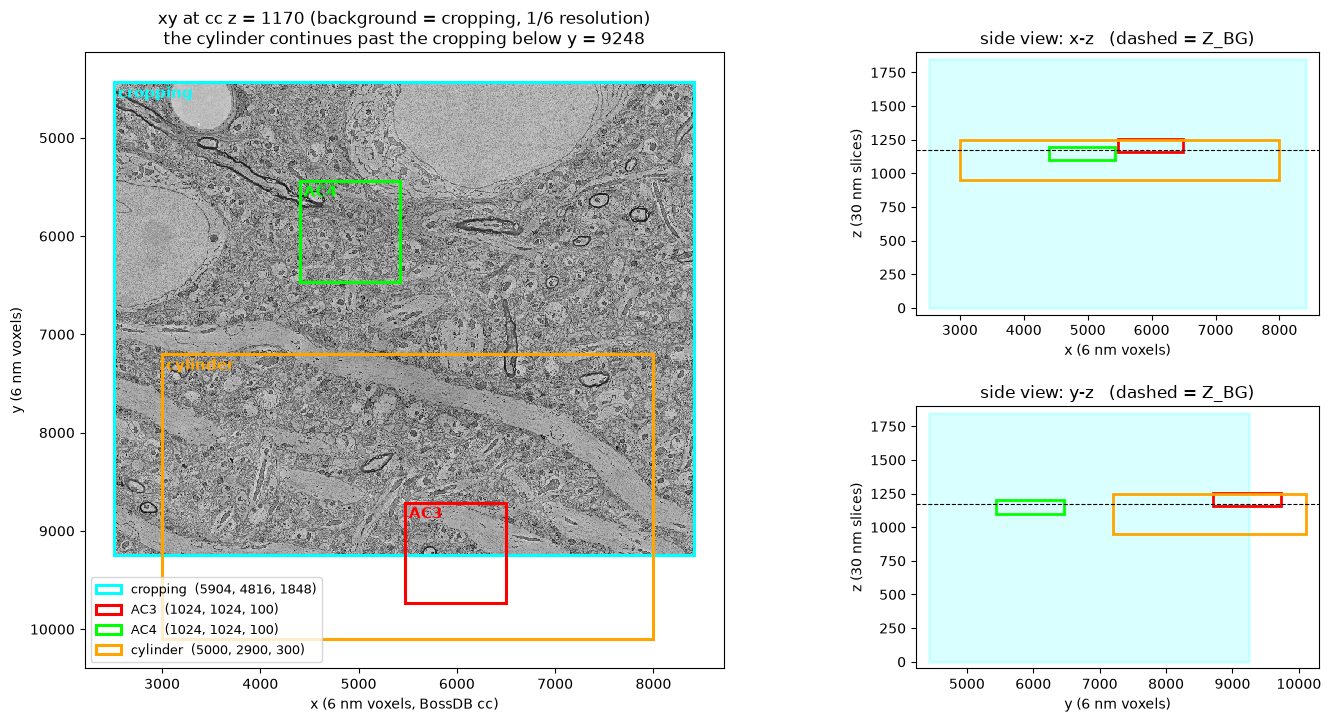

In [5]:
COLORS = {"cropping": "cyan", "cylinder": "orange", "AC3": "red", "AC4": "lime"}
DS = 6
bg = CROP[Z_BG - CZ0, ::DS, ::DS]
ymax = max(r["y"][1] for r in REGIONS.values())

fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[2.0, 1.0], wspace=0.18, hspace=0.35)
ax = fig.add_subplot(gs[:, 0])
ax.imshow(bg, cmap="gray", extent=(CX0, CX1, CY1, CY0), interpolation="nearest")
for n, r in REGIONS.items():
    ax.add_patch(Rectangle((r["x"][0], r["y"][0]), r["x"][1] - r["x"][0], r["y"][1] - r["y"][0],
                           fill=False, ec=COLORS[n], lw=2.2, label=f"{n}  {size(r)}"))
    ax.text(r["x"][0] + 40, r["y"][0] + 40, n, color=COLORS[n], fontsize=11, va="top", weight="bold")
ax.set_xlim(CX0 - 300, CX1 + 300)
ax.set_ylim(ymax + 300, CY0 - 300)
ax.set_xlabel("x (6 nm voxels, BossDB cc)")
ax.set_ylabel("y (6 nm voxels)")
ax.set_title(f"xy at cc z = {Z_BG} (background = cropping, 1/{DS} resolution)\nthe cylinder continues past the cropping below y = {CY1}")
ax.legend(loc="lower left", fontsize=9)

for k, (axis, label) in enumerate((("x", "x"), ("y", "y"))):
    a2 = fig.add_subplot(gs[k, 1])
    for n, r in REGIONS.items():
        a2.add_patch(Rectangle((r[axis][0], r["z"][0]), r[axis][1] - r[axis][0], r["z"][1] - r["z"][0],
                               fill=(n == "cropping"), alpha=0.15 if n == "cropping" else 1, fc=COLORS[n],
                               ec=COLORS[n], lw=2))
    a2.axhline(Z_BG, color="k", ls="--", lw=0.8)
    lim = [min(r[axis][0] for r in REGIONS.values()), max(r[axis][1] for r in REGIONS.values())]
    a2.set_xlim(lim[0] - 200, lim[1] + 200)
    a2.set_ylim(CZ0 - 50, CZ1 + 50)
    a2.set_xlabel(f"{label} (6 nm voxels)")
    a2.set_ylabel("z (30 nm slices)")
    a2.set_title(f"side view: {label}-z   (dashed = Z_BG)")
plt.show()

## 4. Pixel-level registration: are AC3 / AC4 / cylinder really where the doc says?

Each `_cc_` crop is located inside the cropping with the documented offsets and orientation (AC4 stored with z, y and
x reversed, AC3 with z reversed) and compared voxel by voxel. A z-shifted copy is the negative control: if the
comparison cannot tell a 1-slice shift from the right place it is not testing anything.

[PASS] every file used below is listed in DATASETS.md
[PASS] AC4_cc (z,y,x flipped) == cropping at the doc offset  --  {'equal': True, 'frac_equal': 1.0, 'mean_abs': 0.0, 'max_abs': 0}
[PASS] AC3_cc (z flipped), first 536 of 1024 rows == cropping at the doc offset  --  {'equal': True, 'frac_equal': 1.0, 'mean_abs': 0.0, 'max_abs': 0}
[PASS] cylinder image == cropping at the doc offset (NCC >= 0.98, mean |diff| <= 5), slices [0, 100, 200, 299]  --  z0: NCC 0.9955, mean|d| 2.57, equal 12.5%; z100: NCC 0.9950, mean|d| 2.60, equal 12.4%; z200: NCC 0.9958, mean|d| 2.44, equal 13.6%; z299: NCC 0.9958, mean|d| 2.60, equal 12.4%
[INFO] cylinder image is not byte-identical to cc  --  small grey-level differences (see above); the cylinder norm max is 251 vs 255 in cc
[PASS] AC3: registration has a unique minimum at dz = 0 (negative control)  --  mean |diff| by dz: -3:33.6, -2:31.7, -1:26.3, +0:0.0, +1:25.6, +2:31.0, +3:32.7
[PASS] AC4: registration has a unique minimum at dz = 0 (negative contro

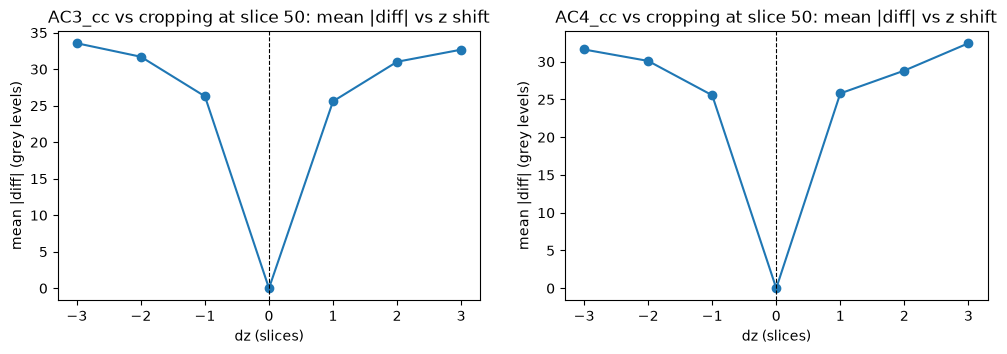

In [6]:
AC_FILES = {
    "AC3_em": "AC3_em_inputs.h5", "AC3_cc": "AC3_cc_inputs.h5", "AC3_lab": "AC3_labels.h5",
    "AC4_em": "AC4_em_inputs.h5", "AC4_cc": "AC4_cc_inputs.h5", "AC4_lab": "AC4_labels.h5",
    "test_em": "test_em_inputs.h5", "train_em": "train_em_inputs.h5", "train_lab": "train_labels.h5",
}
check("every file used below is listed in DATASETS.md", all(f in DOC_TEXT for f in AC_FILES.values()))
AC = {k: vol(f)[...] for k, f in AC_FILES.items()}     # 9 stacks of 100 MB


def crop_slices(x, y, z):
    return (slice(z[0] - CZ0, z[1] - CZ0), slice(y[0] - CY0, y[1] - CY0), slice(x[0] - CX0, x[1] - CX0))


# stored orientation -> cropping orientation
ORIENT = {"AC4": (slice(None, None, -1),) * 3, "AC3": (slice(None, None, -1), slice(None), slice(None))}

# --- AC4: fully inside the cropping
r = REGIONS["AC4"]
a = AC["AC4_cc"][ORIENT["AC4"]]
b = CROP[crop_slices(r["x"], r["y"], r["z"])]
res = compare(a, b)
check("AC4_cc (z,y,x flipped) == cropping at the doc offset", res["equal"], str(res))

# --- AC3: only the rows with y < CY1 are inside the cropping
r = REGIONS["AC3"]
rows = min(r["y"][1], CY1) - r["y"][0]
a = AC["AC3_cc"][ORIENT["AC3"]][:, :rows, :]
b = CROP[crop_slices(r["x"], (r["y"][0], r["y"][0] + rows), r["z"])]
res = compare(a, b)
check(f"AC3_cc (z flipped), first {rows} of 1024 rows == cropping at the doc offset", res["equal"], str(res))

# --- cylinder: 4 slices (the full overlap is 3 GB). Not byte-identical to cc, so use a tolerance.
r = REGIONS["cylinder"]
rows = min(r["y"][1], CY1) - r["y"][0]
cyl_v = vol(CYL_VOL)
res_all = []
for zi in (0, 100, 200, size(r)[2] - 1):
    a = cyl_v[zi, :rows, :]
    b = CROP[r["z"][0] + zi - CZ0, r["y"][0] - CY0:r["y"][0] - CY0 + rows, r["x"][0] - CX0:r["x"][1] - CX0]
    res_all.append((zi, compare(a, b), ncc(a, b)))
check(f"cylinder image == cropping at the doc offset (NCC >= 0.98, mean |diff| <= 5), slices {[z for z, _, _ in res_all]}",
      all(n_ >= 0.98 and c["mean_abs"] <= 5 for _, c, n_ in res_all),
      "; ".join(f"z{z}: NCC {n_:.4f}, mean|d| {c['mean_abs']:.2f}, equal {c['frac_equal']:.1%}" for z, c, n_ in res_all))
info("cylinder image is not byte-identical to cc", "small grey-level differences (see above); the cylinder norm max is 251 vs 255 in cc")

# --- negative control: shift the cropping read by dz slices
def shift_curve(name, k):
    r = REGIONS[name]
    rows = min(r["y"][1], CY1) - r["y"][0]
    a = AC[f"{name}_cc"][ORIENT[name]][k, :rows, :]
    out = {}
    for dz in range(-3, 4):
        b = CROP[r["z"][0] + k + dz - CZ0, r["y"][0] - CY0:r["y"][0] - CY0 + rows, r["x"][0] - CX0:r["x"][1] - CX0]
        out[dz] = compare(a, b)["mean_abs"]
    return out


SHIFT = {n: shift_curve(n, AC_SLICE) for n in ("AC3", "AC4")}
for n, c in SHIFT.items():
    best = min(c, key=c.get)
    check(f"{n}: registration has a unique minimum at dz = 0 (negative control)",
          best == 0 and all(c[d] > 5 for d in c if d != 0), "mean |diff| by dz: " + ", ".join(f"{d:+d}:{v:.1f}" for d, v in c.items()))

# --- em vs cc: same stored index = same section (the doc's 'z + 2' mapping), checked by correlation
for n in ("AC3", "AC4"):
    em, cc = AC[f"{n}_em"], AC[f"{n}_cc"]
    c = {d: ncc(em[AC_SLICE], cc[AC_SLICE + d]) for d in range(-2, 3)}
    check(f"{n}: em[k] correlates best with cc[k] (same stored index)", max(c, key=c.get) == 0,
          ", ".join(f"{d:+d}:{v:.3f}" for d, v in c.items()))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax_, n in zip(axs, SHIFT):
    ax_.plot(list(SHIFT[n]), list(SHIFT[n].values()), "o-")
    ax_.axvline(0, color="k", ls="--", lw=0.8)
    ax_.set_title(f"{n}_cc vs cropping at slice {AC_SLICE}: mean |diff| vs z shift")
    ax_.set_xlabel("dz (slices)")
    ax_.set_ylabel("mean |diff| (grey levels)")
plt.show()

## 5. AC3 / AC4 stacks: em vs cc vs labels

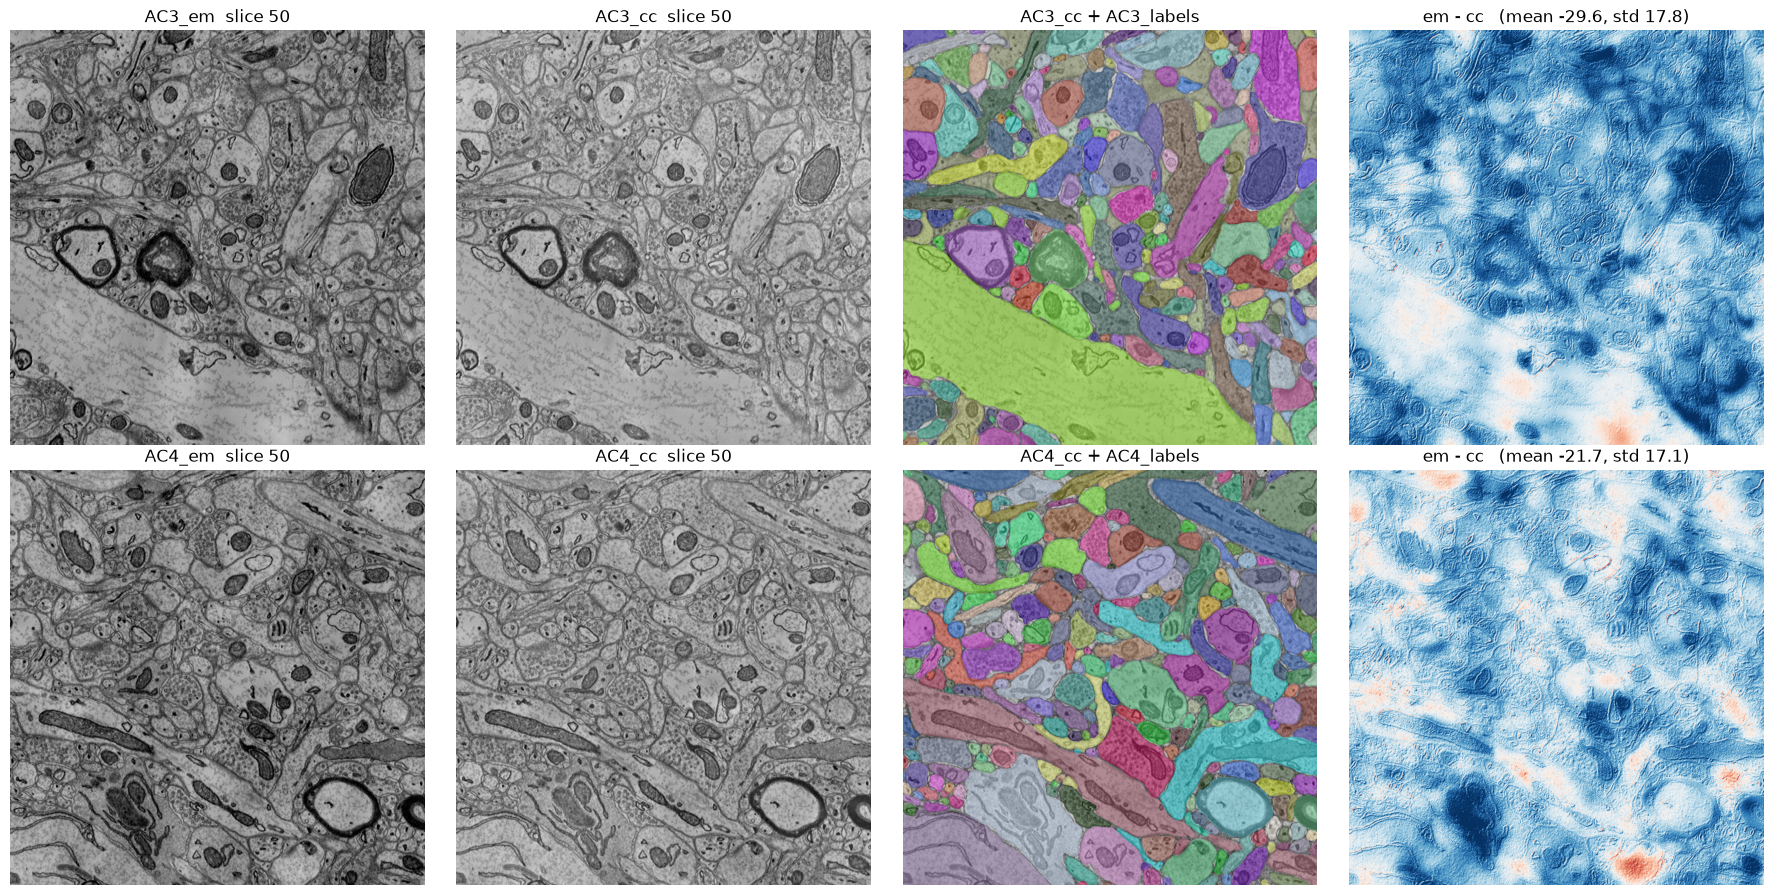

In [7]:
def label_rgb(lab, seed=0):
    rng = np.random.RandomState(seed)
    pal = rng.rand(int(lab.max()) + 1, 3)
    pal[0] = 0
    return pal[lab]


fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for row, n in enumerate(("AC3", "AC4")):
    em, cc, lab = AC[f"{n}_em"][AC_SLICE], AC[f"{n}_cc"][AC_SLICE], AC[f"{n}_lab"][AC_SLICE]
    axs[row, 0].imshow(em, cmap="gray", vmin=0, vmax=255)
    axs[row, 0].set_title(f"{n}_em  slice {AC_SLICE}")
    axs[row, 1].imshow(cc, cmap="gray", vmin=0, vmax=255)
    axs[row, 1].set_title(f"{n}_cc  slice {AC_SLICE}")
    axs[row, 2].imshow(cc, cmap="gray", vmin=0, vmax=255)
    axs[row, 2].imshow(label_rgb(lab), alpha=np.where(lab > 0, 0.45, 0.0))
    axs[row, 2].set_title(f"{n}_cc + {n}_labels")
    d = em.astype(np.int16) - cc.astype(np.int16)
    im = axs[row, 3].imshow(d, cmap="RdBu_r", vmin=-60, vmax=60)
    axs[row, 3].set_title(f"em - cc   (mean {d.mean():+.1f}, std {d.std():.1f})")
    for a_ in axs[row]:
        a_.axis("off")
fig.tight_layout()
plt.show()

## 6. Contrast: `_em_` swings between neighbouring slices, `_cc_` is flat

The doc says the uncorrected stacks have slice-mean brightness that swings by ~20 grey levels between neighbouring
slices and the contrast-corrected ones are flat.

stack         mean  max |d mean|  median |d mean|   range
AC3_em       151.9         79.36            17.26    99.7
AC3_cc       148.7          0.45             0.05     1.5
AC4_em       129.1         81.95            14.64   104.6
AC4_cc       136.4          0.95             0.10     7.3
test_em      151.9         79.36            17.26    99.7
train_em     128.9         81.95            14.76   104.6
[PASS] AC3: em median slice-to-slice step 10-25 grey levels, cc at least 5x flatter  --  median step em 17.3, cc 0.05; max step em 79.4, cc 0.5
[PASS] AC4: em median slice-to-slice step 10-25 grey levels, cc at least 5x flatter  --  median step em 14.6, cc 0.10; max step em 81.9, cc 1.0


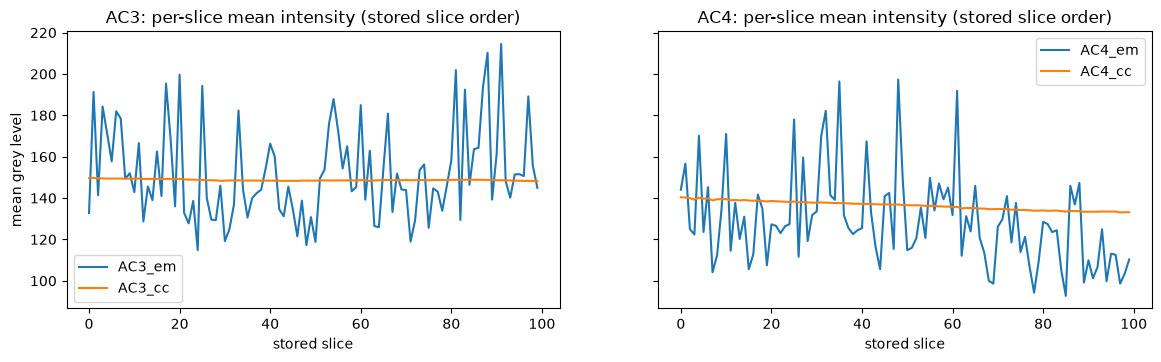

In [8]:
STACKS = ["AC3_em", "AC3_cc", "AC4_em", "AC4_cc", "test_em", "train_em"]
means = {k: AC[k].reshape(100, -1).mean(1) for k in STACKS}
swing = {k: float(np.abs(np.diff(means[k])).max()) for k in STACKS}
print(f"{'stack':10s} {'mean':>7s} {'max |d mean|':>13s} {'median |d mean|':>16s} {'range':>7s}")
for k in STACKS:
    d = np.abs(np.diff(means[k]))
    print(f"{k:10s} {means[k].mean():7.1f} {d.max():13.2f} {np.median(d):16.2f} {np.ptp(means[k]):7.1f}")
for n in ("AC3", "AC4"):
    med_em = float(np.median(np.abs(np.diff(means[f"{n}_em"]))))
    med_cc = float(np.median(np.abs(np.diff(means[f"{n}_cc"]))))
    check(f"{n}: em median slice-to-slice step 10-25 grey levels, cc at least 5x flatter",
          10 <= med_em <= 25 and med_cc * 5 <= med_em,
          f"median step em {med_em:.1f}, cc {med_cc:.2f}; max step em {swing[f'{n}_em']:.1f}, cc {swing[f'{n}_cc']:.1f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax_, n in zip(axs, ("AC3", "AC4")):
    ax_.plot(means[f"{n}_em"], label=f"{n}_em")
    ax_.plot(means[f"{n}_cc"], label=f"{n}_cc")
    ax_.set_title(f"{n}: per-slice mean intensity (stored slice order)")
    ax_.set_xlabel("stored slice")
    ax_.legend()
axs[0].set_ylabel("mean grey level")
plt.show()

## 7. Duplicate files and near-copy slices

`test_em_inputs.h5` should equal `AC3_em_inputs.h5`; `train_em_inputs.h5` should equal `AC4_em_inputs.h5` except one
slice. The SNEMI3D challenge stacks contain a slice that is a near-copy of its neighbour (AC3/test: 89 vs 90, train:
33 vs 34); the `_cc_` stacks, built from the original sections, should not.

[PASS] test_em_inputs == AC3_em_inputs
[PASS] train_em_inputs differs from AC4_em_inputs only at slice 33  --  differing slices [np.int64(33)]
stack       argmax k (k vs k+1)  max NCC  median NCC   NCC(89,90)  NCC(33,34)
AC3_em                       89   0.8397      0.5676       0.8397      0.5556
AC3_cc                       10   0.6118      0.5201       0.5602      0.5341
AC4_em                       74   0.6521      0.5215       0.6137      0.4374
AC4_cc                       82   0.6286      0.5040       0.5633      0.4665
test_em                      89   0.8397      0.5676       0.8397      0.5556
train_em                     33   0.9170      0.5230       0.6137      0.9170
[PASS] test_em: the most duplicated neighbour pair is (89, 90)  --  argmax 89, NCC 0.8397 vs median 0.5676
[PASS] AC3_em: the most duplicated neighbour pair is (89, 90)  --  argmax 89, NCC 0.8397 vs median 0.5676
[PASS] train_em: the most duplicated neighbour pair is (33, 34)  --  argmax 33, NCC 0.9170 vs medi

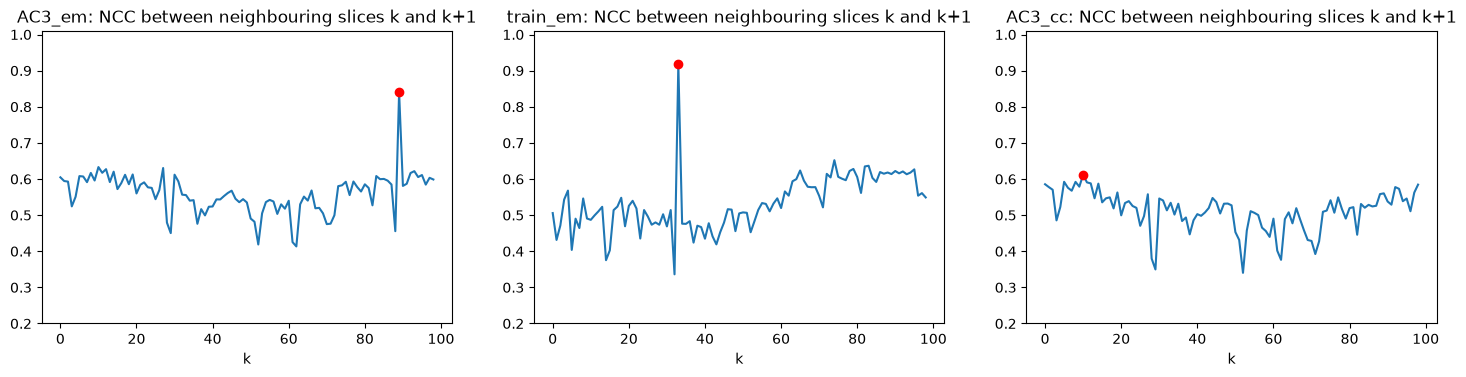

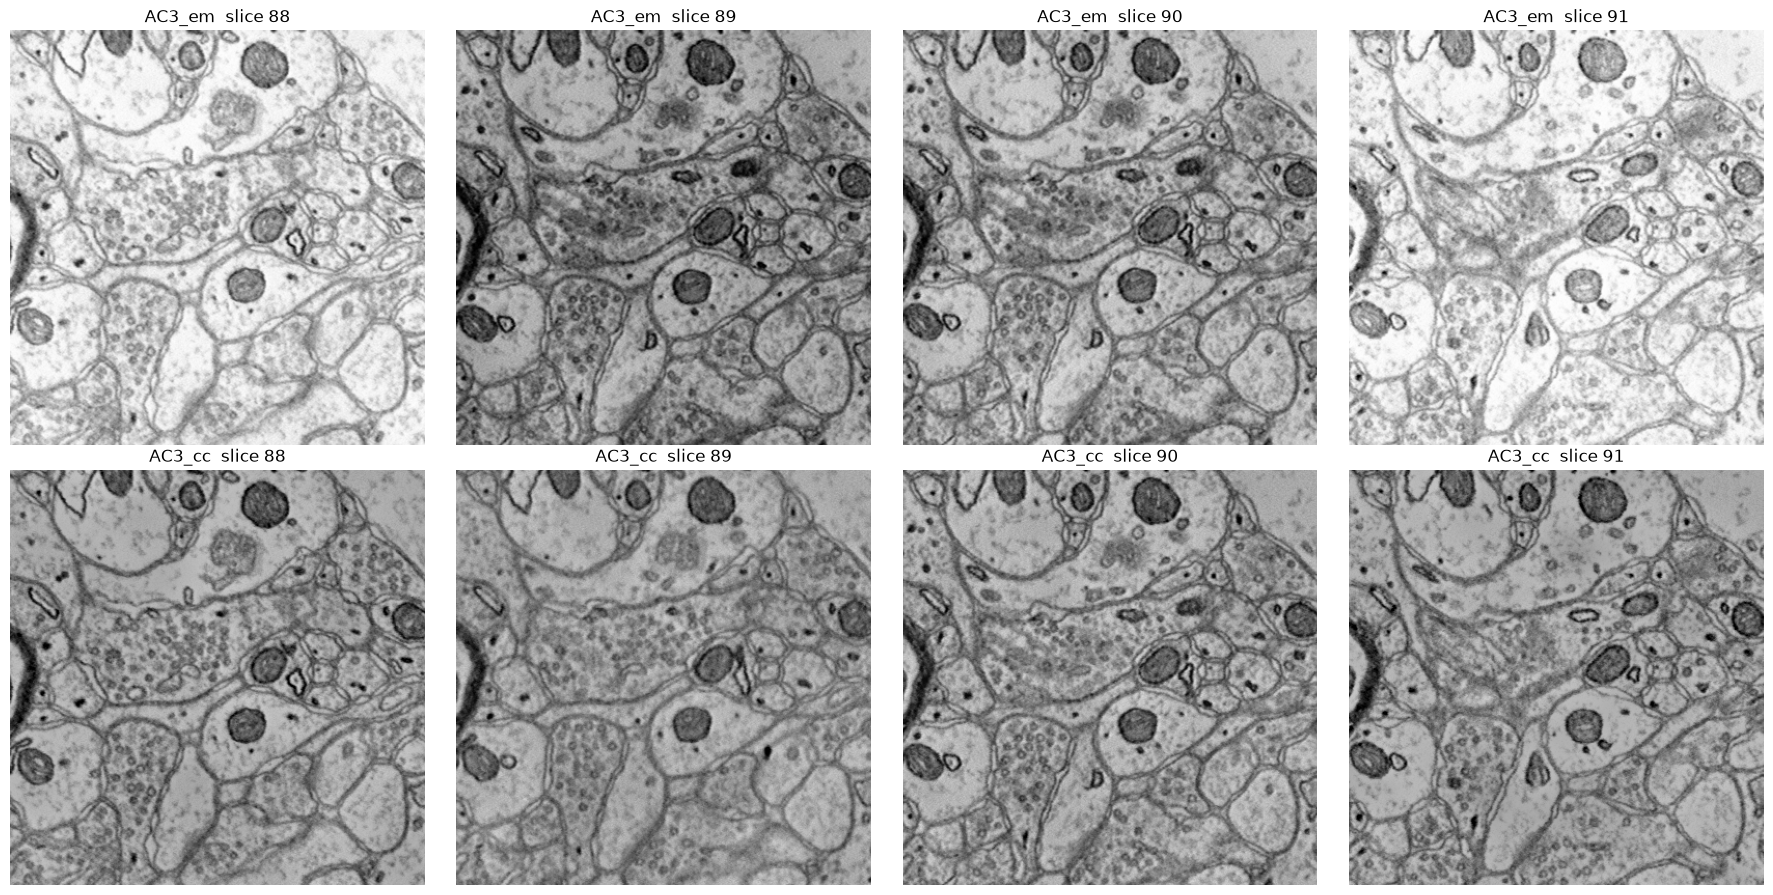

In [9]:
check("test_em_inputs == AC3_em_inputs", np.array_equal(AC["test_em"], AC["AC3_em"]))
diff_sl = np.nonzero((AC["train_em"] != AC["AC4_em"]).reshape(100, -1).any(1))[0]
check("train_em_inputs differs from AC4_em_inputs only at slice 33", list(diff_sl) == [33], f"differing slices {list(diff_sl)}")


def adj_ncc(v):
    return np.array([ncc(v[k], v[k + 1]) for k in range(len(v) - 1)])


ADJ = {k: adj_ncc(AC[k]) for k in STACKS}
print(f"{'stack':10s} {'argmax k (k vs k+1)':>20s} {'max NCC':>8s} {'median NCC':>11s}   NCC(89,90)  NCC(33,34)")
for k in STACKS:
    a = ADJ[k]
    print(f"{k:10s} {int(a.argmax()):20d} {a.max():8.4f} {np.median(a):11.4f}   {a[89]:10.4f}  {a[33]:10.4f}")
for k, want in (("test_em", 89), ("AC3_em", 89), ("train_em", 33)):
    check(f"{k}: the most duplicated neighbour pair is ({want}, {want + 1})", int(ADJ[k].argmax()) == want,
          f"argmax {int(ADJ[k].argmax())}, NCC {ADJ[k].max():.4f} vs median {np.median(ADJ[k]):.4f}")
check("AC3_cc has no near-copy at (89, 90)", ADJ["AC3_cc"][89] < ADJ["AC3_em"][89] - 0.02 and int(ADJ["AC3_cc"].argmax()) != 89,
      f"cc {ADJ['AC3_cc'][89]:.4f} vs em {ADJ['AC3_em'][89]:.4f}")
check("AC4_em has no near-copy at (33, 34)", ADJ["AC4_em"][33] < ADJ["train_em"][33] - 0.02 and int(ADJ["AC4_em"].argmax()) != 33,
      f"AC4_em {ADJ['AC4_em'][33]:.4f} vs train_em {ADJ['train_em'][33]:.4f}")


# 'the labels fit the real section better': membranes are dark, so the image under the label boundaries should be
# darker (relative to the slice mean) when the image really is the labelled section
def boundary_darkness(img, lab):
    b = np.zeros(lab.shape, bool)
    b[:, 1:] |= lab[:, 1:] != lab[:, :-1]
    b[1:, :] |= lab[1:, :] != lab[:-1, :]
    return float(img[b].mean() / img.mean())


rows_ = []
for k in (87, 88, 89, 90, 91):
    rows_.append((k, boundary_darkness(AC["AC3_em"][k], AC["AC3_lab"][k]), boundary_darkness(AC["AC3_cc"][k], AC["AC3_lab"][k])))
print("\nAC3 label-boundary intensity / slice mean (lower = labels sit on darker membranes = better fit)")
print("slice     em      cc")
for k, e, c in rows_:
    print(f"{k:5d} {e:7.3f} {c:7.3f}")
e89, c89 = rows_[2][1], rows_[2][2]
check("AC3 slice 89: labels fit cc better than em", c89 < e89, f"cc {c89:.3f} vs em {e89:.3f}", warn=True)

fig, axs = plt.subplots(1, 3, figsize=(18, 3.8))
for ax_, (n, ks) in zip(axs, (("AC3_em", (89,)), ("train_em", (33,)), ("AC3_cc", (89,)))):
    ax_.plot(ADJ[n])
    ax_.scatter([int(ADJ[n].argmax())], [ADJ[n].max()], color="r", zorder=3)
    ax_.set_title(f"{n}: NCC between neighbouring slices k and k+1")
    ax_.set_xlabel("k")
    ax_.set_ylim(0.2, 1.01)
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for col, k in enumerate((88, 89, 90, 91)):
    for row, name in enumerate(("AC3_em", "AC3_cc")):
        axs[row, col].imshow(AC[name][k][300:700, 300:700], cmap="gray", vmin=0, vmax=255)
        axs[row, col].set_title(f"{name}  slice {k}")
        axs[row, col].axis("off")
fig.tight_layout()
plt.show()

## 8. Labels: AC3 / AC4 / train

In [10]:
a, b = AC["AC4_lab"], AC["train_lab"]
bg_a, bg_b, bg_3 = float((a == 0).mean()), float((b == 0).mean()), float((AC["AC3_lab"] == 0).mean())
m = re.search(r"\((\d+) % vs (\d+) %\)", DOC_TEXT)
check("doc quotes 'wider background borders (X % vs Y %)'", m is not None)
if m:
    check(f"train_labels background {bg_b:.1%} vs AC4_labels {bg_a:.1%} matches the doc ({m.group(1)} % vs {m.group(2)} %)",
          round(bg_b * 100) == int(m.group(1)) and round(bg_a * 100) == int(m.group(2)))
info("AC3_labels background fraction", f"{bg_3:.1%}")
check("train_labels foreground is a subset of AC4_labels foreground", not ((b > 0) & (a == 0)).any())

both = (a > 0) & (b > 0)
key = (a[both].astype(np.uint32) << 16) | b[both].astype(np.uint32)
pairs, cnt = np.unique(key, return_counts=True)
pa, pb = pairs >> 16, pairs & 0xFFFF
best = {}                                      # AC4 id -> (train id with most overlapping voxels, its count)
for p_a, p_b, c_ in zip(pa, pb, cnt):
    if p_a not in best or c_ > best[p_a][1]:
        best[p_a] = (p_b, c_)
agree = sum(c for _, c in best.values()) / cnt.sum()
split_ids = sorted({int(p) for p in pa if (pa == p).sum() > 1})
check("AC4_labels -> train_labels: each AC4 id maps to one train id for >= 99.9% of overlapping voxels",
      agree >= 0.999, f"{agree:.5%} agree; {len(split_ids)} AC4 ids split across 2 train ids: {split_ids}")
del key, pairs, cnt, pa, pb, both

[PASS] doc quotes 'wider background borders (X % vs Y %)'
[PASS] train_labels background 15.1% vs AC4_labels 10.2% matches the doc (15 % vs 10 %)
[INFO] AC3_labels background fraction  --  7.6%
[PASS] train_labels foreground is a subset of AC4_labels foreground
[PASS] AC4_labels -> train_labels: each AC4 id maps to one train id for >= 99.9% of overlapping voxels  --  99.99987% agree; 4 AC4 ids split across 2 train ids: [2, 13, 169, 246]


## 9. Kasthuri cropping: tissue everywhere, and the slice-432 defect

The doc says the cropping is the largest crop with tissue in every voxel. Exact-zero voxels are the cheapest proxy:
the full-depth columns at the corners and edge midpoints should be (almost) free of them. Slice 432 is documented as
having a black blob.

scanned 9 full-depth 256 x 256 columns in 2 s
fraction of exact-zero voxels: {'NW': '0.0035%', 'NE': '0.0261%', 'SW': '0.0081%', 'SE': '0.0160%', 'N': '0.0141%', 'S': '0.0056%', 'W': '0.0058%', 'E': '0.0071%', 'centre': '0.0045%'}
[PASS] no outside-the-tissue (zero) voxels at the corners / edges of the cropping  --  max 0.0261%; centre 0.0045%
[PASS] doc quotes the slice-432 defect
slice 432: zero fraction 0.608% (neighbours 0.006%, 0.005%); largest black blob bbox x 4451-5068, y 580-975
[PASS] slice 432: black fraction ~ documented  --  0.61% vs doc 0.6 %
[PASS] slice 432: blob bbox within 60 px of the documented x/y range  --  (4451, 5068, 580, 975) vs doc (4450, 5070, 580, 975)
[PASS] slice 432 is the only defective neighbour (431 / 433 have ~no zeros)  --  [6.108955919293412e-05, 5.046834625322997e-05]


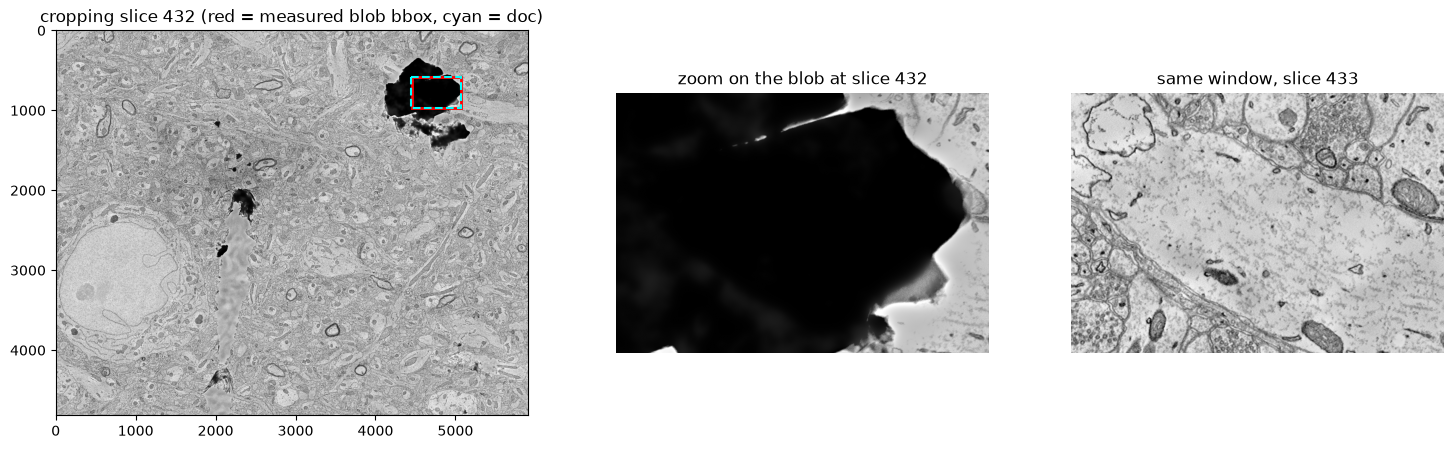

In [11]:
W = 256
H_, W_ = CROP.shape[1], CROP.shape[2]
spots = {"NW": (0, 0), "NE": (0, W_ - W), "SW": (H_ - W, 0), "SE": (H_ - W, W_ - W),
         "N": (0, W_ // 2 - W // 2), "S": (H_ - W, W_ // 2 - W // 2), "W": (H_ // 2 - W // 2, 0),
         "E": (H_ // 2 - W // 2, W_ - W), "centre": (H_ // 2 - W // 2, W_ // 2 - W // 2)}
zero_frac = {}
t0 = time.time()
for k, (y0, x0) in spots.items():
    zero_frac[k] = float((CROP[:, y0:y0 + W, x0:x0 + W] == 0).mean())
print(f"scanned {len(spots)} full-depth 256 x 256 columns in {time.time() - t0:.0f} s")
print("fraction of exact-zero voxels:", {k: f"{v:.4%}" for k, v in zero_frac.items()})
check("no outside-the-tissue (zero) voxels at the corners / edges of the cropping",
      max(v for k, v in zero_frac.items() if k != "centre") < 0.005,
      f"max {max(zero_frac.values()):.4%}; centre {zero_frac['centre']:.4%}")

# slice 432
Z_DEF = 432
s = CROP[Z_DEF]
zero = s == 0
lab_, n_ = ndi.label(ndi.binary_closing(zero, iterations=3))
sizes = ndi.sum(zero, lab_, range(1, n_ + 1)) if n_ else []
big = 1 + int(np.argmax(sizes)) if n_ else None
ys_, xs_ = np.nonzero(lab_ == big)
bbox = (int(xs_.min()), int(xs_.max()), int(ys_.min()), int(ys_.max()))
frac = float(zero.mean())
neigh = [float((CROP[z] == 0).mean()) for z in (Z_DEF - 1, Z_DEF + 1)]
mm = re.search(r"([\d.]+) % black blob near x (\d+)-(\d+),\s+y (\d+)-(\d+)", DOC_TEXT)
check("doc quotes the slice-432 defect", mm is not None)
print(f"slice {Z_DEF}: zero fraction {frac:.3%} (neighbours {neigh[0]:.3%}, {neigh[1]:.3%}); "
      f"largest black blob bbox x {bbox[0]}-{bbox[1]}, y {bbox[2]}-{bbox[3]}")
if mm:
    d_frac, dx0, dx1, dy0, dy1 = float(mm.group(1)), *(int(g) for g in mm.groups()[1:])
    check("slice 432: black fraction ~ documented", abs(frac * 100 - d_frac) < 0.2, f"{frac:.2%} vs doc {d_frac} %")
    check("slice 432: blob bbox within 60 px of the documented x/y range",
          all(abs(a - b) <= 60 for a, b in zip(bbox, (dx0, dx1, dy0, dy1))), f"{bbox} vs doc {(dx0, dx1, dy0, dy1)}")
    check("slice 432 is the only defective neighbour (431 / 433 have ~no zeros)", max(neigh) < 0.0005, f"{neigh}")

fig, axs = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
axs[0].imshow(s[::6, ::6], cmap="gray", extent=(0, W_, H_, 0))
axs[0].add_patch(Rectangle((bbox[0], bbox[2]), bbox[1] - bbox[0], bbox[3] - bbox[2], fill=False, ec="r", lw=2))
if mm:
    axs[0].add_patch(Rectangle((dx0, dy0), dx1 - dx0, dy1 - dy0, fill=False, ec="cyan", lw=1.5, ls="--"))
axs[0].set_title(f"cropping slice {Z_DEF} (red = measured blob bbox, cyan = doc)")
pad = 60
y0_, y1_, x0_, x1_ = max(0, bbox[2] - pad), bbox[3] + pad, max(0, bbox[0] - pad), bbox[1] + pad
axs[1].imshow(s[y0_:y1_, x0_:x1_], cmap="gray", vmin=0, vmax=255)
axs[1].set_title(f"zoom on the blob at slice {Z_DEF}")
axs[2].imshow(CROP[Z_DEF + 1][y0_:y1_, x0_:x1_], cmap="gray", vmin=0, vmax=255)
axs[2].set_title(f"same window, slice {Z_DEF + 1}")
for a_ in axs[1:]:
    a_.axis("off")
plt.show()

## 10. Kasthuri cylinder: label coverage

scanned 300 of 300 slices in 55 s
labelled fraction: overall 41.6%; per slice min 7.8%, median 46.0%, max 64.0%; slices with no label: 0
[PASS] doc quotes the cylinder label coverage
[PASS] cylinder: overall labelled fraction ~ documented  --  41.6% vs doc 42 %
[PASS] cylinder: per-slice range ~ documented  --  7.8%-64.0% vs doc 8-64 %
[PASS] cylinder: every scanned slice has labels (doc: 'every slice has some')  --  0 empty slices
[PASS] cylinder segmentation and image have the same shape  --  (300, 2900, 5000) vs (300, 2900, 5000)


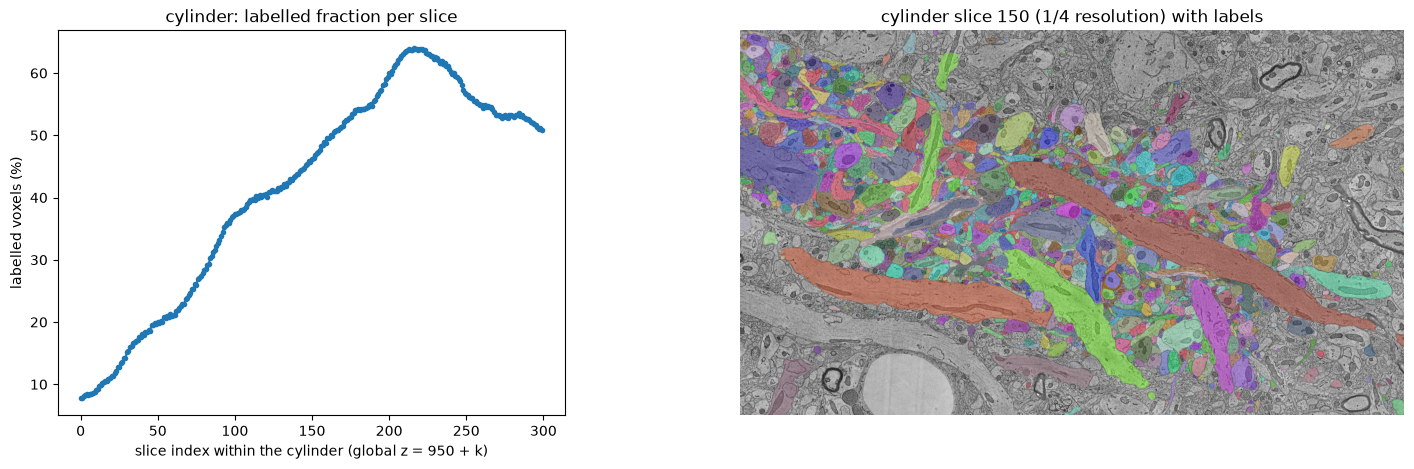

In [12]:
seg = vol(CYL_SEG)
step = 5 if CYL_FULL_SCAN else 20
frac_lab = {}
t0 = time.time()
for z0 in range(0, seg.shape[0], step):
    blk = seg[z0:z0 + 5]                          # one chunk-aligned block of 5 slices
    for i, v in enumerate((blk > 0).reshape(blk.shape[0], -1).mean(1)):
        frac_lab[z0 + i] = float(v)
zs_ = np.array(sorted(frac_lab))
fr = np.array([frac_lab[z] for z in zs_])
print(f"scanned {len(zs_)} of {seg.shape[0]} slices in {time.time() - t0:.0f} s")
empty = int((fr == 0).sum())
overall = float(fr.mean())
print(f"labelled fraction: overall {overall:.1%}; per slice min {fr.min():.1%}, median {np.median(fr):.1%}, max {fr.max():.1%}; "
      f"slices with no label: {empty}")

mm = re.search(r"labels cover ~(\d+) % of voxels \((\d+)-(\d+) % per slice\)", DOC_TEXT)
check("doc quotes the cylinder label coverage", mm is not None)
if mm:
    d_all, d_lo, d_hi = (int(g) for g in mm.groups())
    check("cylinder: overall labelled fraction ~ documented", abs(overall * 100 - d_all) <= 1.5, f"{overall:.1%} vs doc {d_all} %",
          warn=not CYL_FULL_SCAN)
    check("cylinder: per-slice range ~ documented", abs(fr.min() * 100 - d_lo) <= 1.5 and abs(fr.max() * 100 - d_hi) <= 1.5,
          f"{fr.min():.1%}-{fr.max():.1%} vs doc {d_lo}-{d_hi} %", warn=not CYL_FULL_SCAN)
check("cylinder: every scanned slice has labels (doc: 'every slice has some')", empty == 0, f"{empty} empty slices")
check("cylinder segmentation and image have the same shape", seg.shape == cyl_v.shape, f"{seg.shape} vs {cyl_v.shape}")

zm = seg.shape[0] // 2
img = cyl_v[zm, ::4, ::4]
lab = seg[zm - zm % 5:zm - zm % 5 + 5][zm % 5, ::4, ::4]
fig, axs = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw=dict(width_ratios=[1, 1.5]))
axs[0].plot(zs_, fr * 100, ".-")
axs[0].set_xlabel("slice index within the cylinder (global z = 950 + k)")
axs[0].set_ylabel("labelled voxels (%)")
axs[0].set_title("cylinder: labelled fraction per slice")
axs[1].imshow(img, cmap="gray", vmin=0, vmax=255)
axs[1].imshow(label_rgb(lab.astype(np.int64)), alpha=np.where(lab > 0, 0.45, 0.0))
axs[1].set_title(f"cylinder slice {zm} (1/4 resolution) with labels")
axs[1].axis("off")
plt.show()

## 11. Label distribution and anisotropy

Adapted from the `tmquan/neurons` `01_explore_snemi3d` notebook: background/foreground split, instance-size
histogram (log scale) and the voxel anisotropy. The reference treats AC3 as label-free ("labels never released");
this folder has `AC3_labels.h5`, so the AC3 numbers are shown here too and the provenance is reported as INFO.

[INFO] anisotropy (z / xy voxel size)  --  5.0x  (6 x 6 x 30 nm)
labels                background  foreground  instances  median size   max size
AC3_labels                  7.6%       92.4%        333       88,721 12,726,900
AC4_labels (train)         10.2%       89.8%        400       89,350  4,919,028
train_labels               15.1%       84.9%        400       89,350  4,720,002
[INFO] AC3_labels.h5 is present locally  --  the tmquan/neurons notebook says AC3 labels were never released; confirm provenance


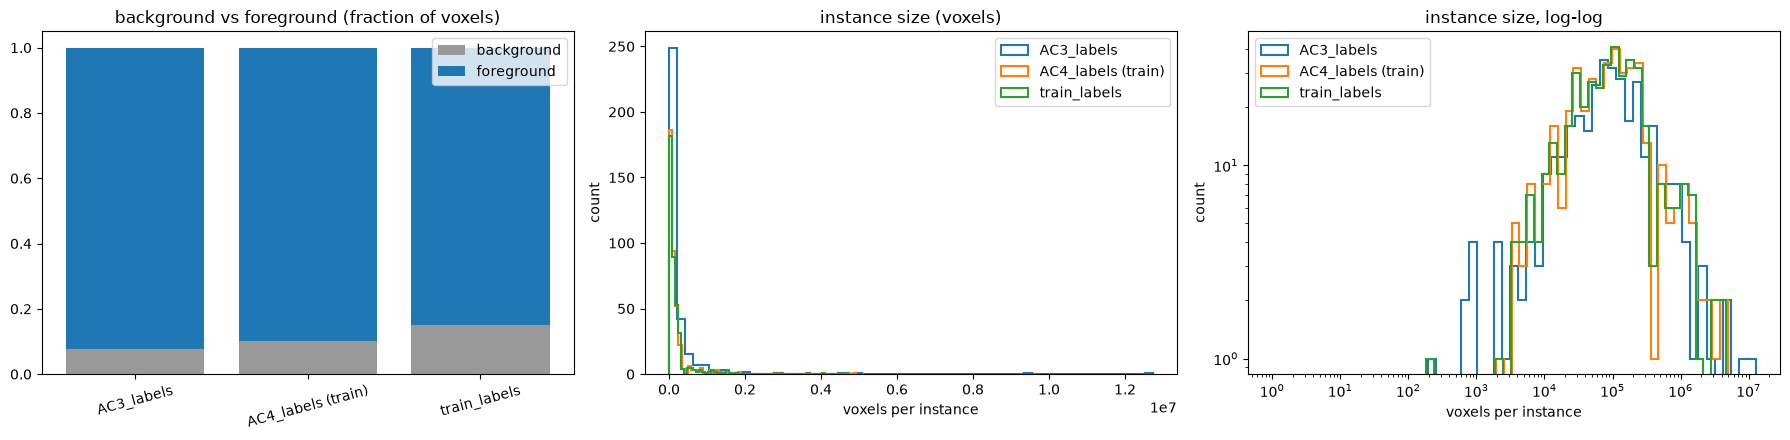

[PASS] AC4_labels and train_labels both have 400 neuron ids (same count; the id map is one-to-one up to 4 splits)  --  AC4 400, train 400


In [13]:
ANISO = 30.0 / 6.0
info("anisotropy (z / xy voxel size)", f"{ANISO:.1f}x  (6 x 6 x 30 nm)")


def label_stats(lab):
    u, c = np.unique(lab, return_counts=True)
    bg = int(c[u == 0].sum())
    return dict(bg_frac=bg / lab.size, n_ids=int((u > 0).sum()), sizes=c[u > 0], total=int(lab.size))


LAB = {"AC3_labels": AC["AC3_lab"], "AC4_labels (train)": AC["AC4_lab"], "train_labels": AC["train_lab"]}
ST = {k: label_stats(v) for k, v in LAB.items()}
print(f"{'labels':20s} {'background':>11s} {'foreground':>11s} {'instances':>10s} {'median size':>12s} {'max size':>10s}")
for k, s in ST.items():
    print(f"{k:20s} {s['bg_frac']:11.1%} {1 - s['bg_frac']:11.1%} {s['n_ids']:10d} "
          f"{int(np.median(s['sizes'])):12,d} {int(s['sizes'].max()):10,d}")
info("AC3_labels.h5 is present locally", "the tmquan/neurons notebook says AC3 labels were never released; confirm provenance")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
names = list(ST)
axes[0].bar(names, [ST[k]["bg_frac"] for k in names], color="0.6", label="background")
axes[0].bar(names, [1 - ST[k]["bg_frac"] for k in names], bottom=[ST[k]["bg_frac"] for k in names],
            color="tab:blue", label="foreground")
axes[0].set_title("background vs foreground (fraction of voxels)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=15)
for k in names:
    axes[1].hist(ST[k]["sizes"], bins=60, histtype="step", label=k, lw=1.5)
    axes[2].hist(ST[k]["sizes"], bins=np.logspace(0, np.log10(ST[k]["sizes"].max()), 60),
                 histtype="step", label=k, lw=1.5)
axes[1].set_title("instance size (voxels)")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_title("instance size, log-log")
for a_ in axes[1:]:
    a_.set_xlabel("voxels per instance")
    a_.set_ylabel("count")
    a_.legend()
fig.tight_layout()
plt.show()

check("AC4_labels and train_labels both have 400 neuron ids (same count; the id map is one-to-one up to 4 splits)",
      ST["AC4_labels (train)"]["n_ids"] == 400 and ST["train_labels"]["n_ids"] == 400,
      f"AC4 {ST['AC4_labels (train)']['n_ids']}, train {ST['train_labels']['n_ids']}", warn=True)

## 12. Summary

In [14]:
order = {"FAIL": 0, "WARN": 1, "INFO": 2, "PASS": 3}
counts = {s: sum(1 for r in RESULTS if r[0] == s) for s in order}
print("  ".join(f"{s}: {n}" for s, n in counts.items()))
print()
for status, name, detail in sorted(RESULTS, key=lambda r: order[r[0]]):
    if status != "PASS":
        print(f"[{status}] {name}" + (f"  --  {detail}" if detail else ""))

print("\nNot verifiable offline (need BossDB / the original SNEMI3D challenge files):")
for s_ in ("AC4_em == BossDB Kasthuri/ac4/em (same flips)", "AC4 labels == Kasthuri/ac4/neuron up to a relabel",
           "AC3_em == SNEMI3D test_inputs.h5 (checked via test_em_inputs.h5 above)",
           "cylinder labels are a crop of kasthuri2015/em/3cylneuron_v1",
           "`images` vs `cc` z-offset of 2 and the sub-voxel residual"):
    print("  -", s_)

FAIL: 0  WARN: 2  INFO: 7  PASS: 96

[WARN] neurons_cc_5000x2900x300_x3000_y7200_z950_volume.h5.norm.json covers the data  --  norm [0, 251] vs data [0, 255] (sampled (6 slices))
[WARN] AC3 slice 89: labels fit cc better than em  --  cc 0.814 vs em 0.793
[INFO] AC3: fraction of the region inside the cropping  --  52.3%
[INFO] AC4: fraction of the region inside the cropping  --  100.0%
[INFO] cylinder: fraction of the region inside the cropping  --  70.6%
[INFO] cylinder image is not byte-identical to cc  --  small grey-level differences (see above); the cylinder norm max is 251 vs 255 in cc
[INFO] AC3_labels background fraction  --  7.6%
[INFO] anisotropy (z / xy voxel size)  --  5.0x  (6 x 6 x 30 nm)
[INFO] AC3_labels.h5 is present locally  --  the tmquan/neurons notebook says AC3 labels were never released; confirm provenance

Not verifiable offline (need BossDB / the original SNEMI3D challenge files):
  - AC4_em == BossDB Kasthuri/ac4/em (same flips)
  - AC4 labels == Kasthuri/ac4/n